In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras

(x_train, y_train), (x_test, y_test) = keras.datasets.mnist.load_data()

print(x_train.shape, y_train.shape)
print(x_test.shape, y_test.shape)
print(x_train.dtype, x_train.min(), x_train.max())

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(60000, 28, 28) (60000,)
(10000, 28, 28) (10000,)
uint8 0 255


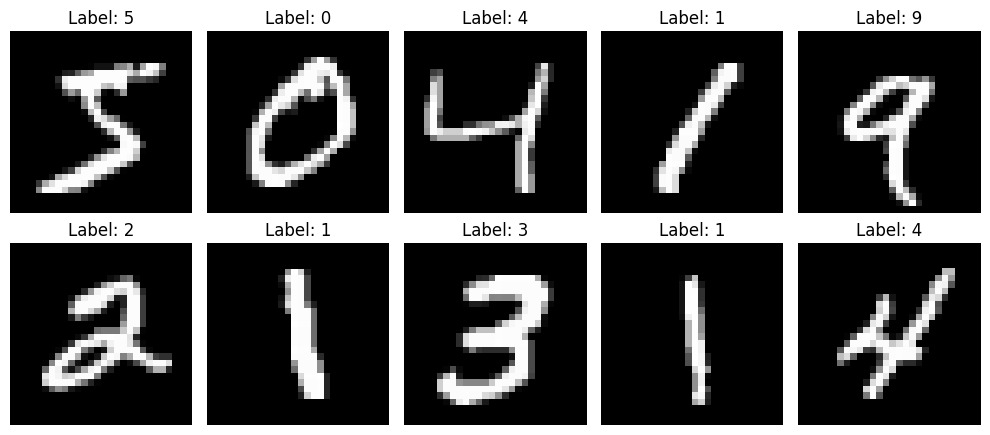

In [2]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow(x_train[i], cmap="gray")
    ax.set_title(f"Label: {y_train[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

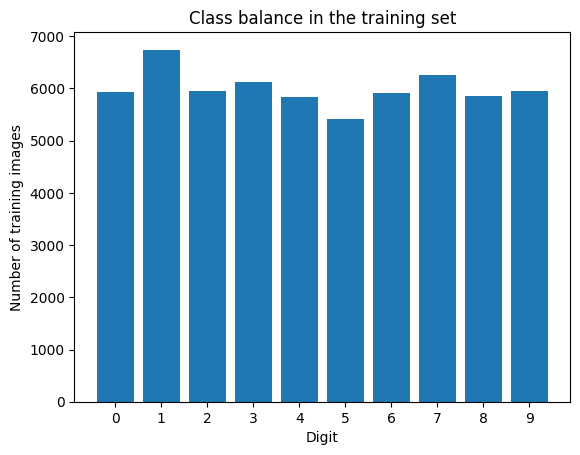

{0: 5923, 1: 6742, 2: 5958, 3: 6131, 4: 5842, 5: 5421, 6: 5918, 7: 6265, 8: 5851, 9: 5949}


In [3]:
digits, counts = np.unique(y_train, return_counts=True)

plt.bar(digits, counts)
plt.xticks(digits)
plt.xlabel("Digit")
plt.ylabel("Number of training images")
plt.title("Class balance in the training set")
plt.show()

print(dict(zip(digits.tolist(), counts.tolist())))

In [4]:
np.set_printoptions(linewidth=200)
print("Label:", y_train[0])
print(x_train[0][8:22, 6:22])

Label: 5
[[  0  18 219 253 253 253 253 253 198 182 247 241   0   0   0   0]
 [  0   0  80 156 107 253 253 205  11   0  43 154   0   0   0   0]
 [  0   0   0  14   1 154 253  90   0   0   0   0   0   0   0   0]
 [  0   0   0   0   0 139 253 190   2   0   0   0   0   0   0   0]
 [  0   0   0   0   0  11 190 253  70   0   0   0   0   0   0   0]
 [  0   0   0   0   0   0  35 241 225 160 108   1   0   0   0   0]
 [  0   0   0   0   0   0   0  81 240 253 253 119  25   0   0   0]
 [  0   0   0   0   0   0   0   0  45 186 253 253 150  27   0   0]
 [  0   0   0   0   0   0   0   0   0  16  93 252 253 187   0   0]
 [  0   0   0   0   0   0   0   0   0   0   0 249 253 249  64   0]
 [  0   0   0   0   0   0   0   0  46 130 183 253 253 207   2   0]
 [  0   0   0   0   0   0  39 148 229 253 253 253 250 182   0   0]
 [  0   0   0   0  24 114 221 253 253 253 253 201  78   0   0   0]
 [  0   0  23  66 213 253 253 253 253 198  81   2   0   0   0   0]]


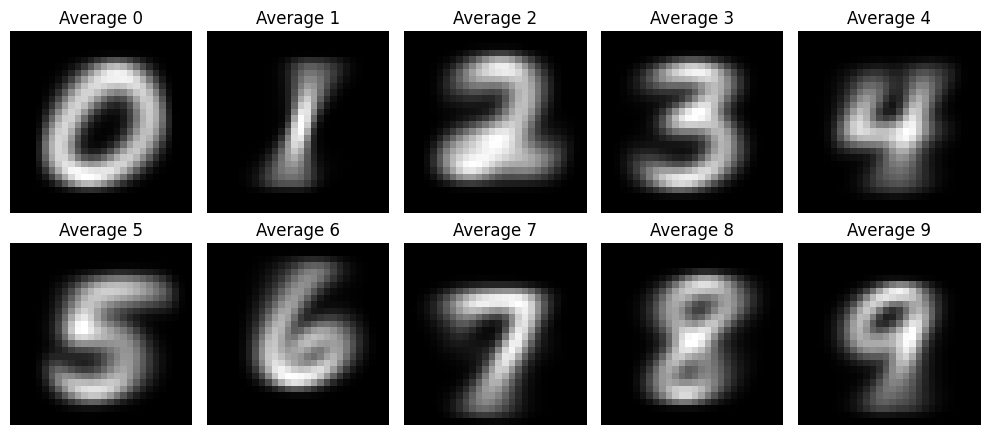

In [5]:
fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for d, ax in enumerate(axes.flat):
    ax.imshow(x_train[y_train == d].mean(axis=0), cmap="gray")
    ax.set_title(f"Average {d}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [6]:
from sklearn.model_selection import train_test_split

x_train_full = x_train.astype("float32") / 255.0
x_test_s = x_test.astype("float32") / 255.0

x_tr, x_val, y_tr, y_val = train_test_split(
    x_train_full, y_train, test_size=0.1, random_state=42, stratify=y_train
)

x_tr_cnn = x_tr[..., np.newaxis]
x_val_cnn = x_val[..., np.newaxis]
x_test_cnn = x_test_s[..., np.newaxis]

print(x_tr_cnn.shape, x_val_cnn.shape, x_test_cnn.shape)
print(x_tr.min(), x_tr.max())

(54000, 28, 28, 1) (6000, 28, 28, 1) (10000, 28, 28, 1)
0.0 1.0


In [7]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

x_tr_flat = x_tr.reshape(len(x_tr), -1)
x_val_flat = x_val.reshape(len(x_val), -1)

print(x_tr_flat.shape)

base_model = LogisticRegression(max_iter=100)
base_model.fit(x_tr_flat, y_tr)

val_pred = base_model.predict(x_val_flat)
print("Baseline validation accuracy:", round(accuracy_score(y_val, val_pred), 4))

(54000, 784)
Baseline validation accuracy: 0.9217


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [8]:
model = keras.Sequential([
    keras.layers.Input(shape=(28, 28, 1)),
    keras.layers.Conv2D(32, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Conv2D(64, (3, 3), activation="relu"),
    keras.layers.MaxPooling2D((2, 2)),
    keras.layers.Flatten(),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(10, activation="softmax"),
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │        16,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 34,826 (136.04 KB)

 Trainable params: 34,826 (136.04 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=2, restore_best_weights=True
)

history = model.fit(
    x_tr_cnn, y_tr,
    validation_data=(x_val_cnn, y_val),
    epochs=15,
    batch_size=128,
    callbacks=[early_stop],
)

Epoch 1/15


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].plot(history.history["accuracy"], label="train")
axes[0].plot(history.history["val_accuracy"], label="validation")
axes[0].set_title("Accuracy")
axes[0].set_xlabel("Epoch")
axes[0].legend()

axes[1].plot(history.history["loss"], label="train")
axes[1].plot(history.history["val_loss"], label="validation")
axes[1].set_title("Loss")
axes[1].set_xlabel("Epoch")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
test_loss, test_acc = model.evaluate(x_test_cnn, y_test, verbose=0)
print("CNN test accuracy:", round(test_acc, 4))

x_test_flat = x_test_s.reshape(len(x_test_s), -1)
base_test_acc = accuracy_score(y_test, base_model.predict(x_test_flat))
print("Baseline test accuracy:", round(base_test_acc, 4))

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns

probs = model.predict(x_test_cnn, verbose=0)
y_pred = probs.argmax(axis=1)

cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicted digit")
plt.ylabel("Actual digit")
plt.title("CNN confusion matrix (test set)")
plt.show()

print(classification_report(y_test, y_pred, digits=3))

wrong = np.where(y_pred != y_test)[0]
print("Number of mistakes:", len(wrong))

fig, axes = plt.subplots(2, 5, figsize=(10, 4.5))
for ax, i in zip(axes.flat, wrong[:10]):
    ax.imshow(x_test[i], cmap="gray")
    ax.set_title(f"True {y_test[i]}, Pred {y_pred[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
import json

model.save("mnist_cnn.keras")

w = model.get_weights()
names = ["conv1_w", "conv1_b", "conv2_w", "conv2_b", "dense_w", "dense_b"]
out = {n: np.round(a, 5).flatten().tolist() for n, a in zip(names, w)}

with open("mnist_weights.json", "w") as f:
    json.dump(out, f, separators=(",", ":"))

print({n: len(v) for n, v in out.items()})